In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Base-2 log-direction finite-shot SPSA for graph-IQP CartPole policies

This is a separate confirmatory study. It preserves the validated finite-shot
notebook and its results, reuses only the verified exact-analytic baselines,
and reruns the 4,096-shot condition with

\[
K=\left\lceil\log_2 p\right\rceil
\]

independent Rademacher directions per update, where \(p\) is the number of
trainable scalar policy weights. All labels use **CartPole-v1/200** because
every episode is explicitly capped at 200 steps.

The notebook computes \(p\) from the actual QASP state tensors and checks it
against the model and architecture formulas. This gives \(p=90\) for the
5-qubit \(L=3\) policy and \(p=65\) for the 10-qubit \(L=1\) policy, hence
\(K=7\) for both. The earlier 45/35 figures inferred from native
parameter-shift counts are effective parameterized gate arguments, not the
optimizer-vector dimension perturbed by SPSA.

Finite action probabilities come from fresh multinomial circuit counts.
Jeffreys smoothing is applied symmetrically:

\[
\widehat p_a=\frac{c_a+0.5}{N+1},\qquad N=4096.
\]

No exact-statevector probability or gradient is used in the finite-shot
losses. Exact Born probabilities are evaluated only as the categorical
distribution from which finite circuit counts are sampled.


In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/qasp-log2-directions-mpl")

import copy
import gc
import hashlib
import json
import math
import platform
import subprocess
import time
from pathlib import Path

import gymnasium as gym
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from IPython.display import display

import qasp
from qasp.rl.model import create_model

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
BASELINE_RESULTS_DIR = ROOT / "tests" / "finite_shot_cartpole_results"
RESULTS_DIR = ROOT / "tests" / "finite_shot_cartpole_log2_directions_results"
FIGURES_DIR = RESULTS_DIR / "figures"
RUNS_DIR = RESULTS_DIR / "runs"
for directory in (RESULTS_DIR, FIGURES_DIR, RUNS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 7,
    "lines.linewidth": 1.8,
})

MASTER_SEEDS_5 = (3, 7, 11, 23, 37)
MASTER_SEEDS_10 = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
CONFIRMATORY_SEEDS_10 = MASTER_SEEDS_10[:5]
CONDITIONS = (
    {"mode": "shots_4096_log2K", "shots": 4096, "gradient_estimator": "spsa"},
)
POLICIES = ("parity", "majority")
N_EPISODES = 500
MAX_STEPS = 200
FINAL_WINDOW = 50
SOLVED_WINDOW = 100
SOLVED_THRESHOLD = 195.0

TRAINING = {
    "gamma": 0.99,
    "lr": 3e-2,
    "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)",
    "batch_episodes": 5,
    "normalize_returns": True,
    "baseline_type": "ema",
    "baseline_momentum": 0.05,
    "entropy_coef": 5e-3,
    "max_grad_norm": 1.0,
    "spsa_directions_rule": "ceil(log2(total trainable scalar parameters))",
    "spsa_c0": 0.1,
    "spsa_gamma": 0.101,
    "pseudocount_alpha": 0.5,
}

print("PennyLane", qml.__version__, "| PyTorch", torch.__version__)
print("QASP root:", ROOT)
print("Preserved baseline results:", BASELINE_RESULTS_DIR)
print("New results:", RESULTS_DIR)
print("Confirmatory conditions:", CONDITIONS)
print("5q seeds:", MASTER_SEEDS_5)
print("10q seeds used:", CONFIRMATORY_SEEDS_10,
      "(reduced from", MASTER_SEEDS_10, "after timing pilot)")


PennyLane 0.42.2 | PyTorch 2.7.0
QASP root: .
Preserved baseline results: ./tests/finite_shot_cartpole_results
New results: ./tests/finite_shot_cartpole_log2_directions_results
Confirmatory conditions: ({'mode': 'shots_4096_log2K', 'shots': 4096, 'gradient_estimator': 'spsa'},)
5q seeds: (3, 7, 11, 23, 37)
10q seeds used: (3, 7, 11, 23, 37) (reduced from (3, 7, 11, 23, 37, 41, 43, 47, 53, 59) after timing pilot)


In [2]:
EXPANDER_EDGES = [
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
]

ARCHITECTURES = {
    "ring_5_L3": {
        "label": "5-qubit ring, L=3",
        "n_qubits": 5,
        "n_layers": 3,
        "edges": [(i, (i + 1) % 5) for i in range(5)],
        "measurement_wires": list(range(5)),
        "initializer": "normal_0_1",
        "seeds": MASTER_SEEDS_5,
        "source_depth_reason": "largest majority advantage among the 5q depth sweep",
    },
    "expander_10_L1": {
        "label": "10-qubit cubic expander, L=1",
        "n_qubits": 10,
        "n_layers": 1,
        "edges": EXPANDER_EDGES,
        "measurement_wires": list(range(9)),
        "initializer": "uniform",
        "seeds": CONFIRMATORY_SEEDS_10,
        "source_depth_reason": "largest/cheapest 10q majority contrast in the source sweep",
    },
}

g = nx.Graph()
g.add_nodes_from(range(10))
g.add_edges_from(EXPANDER_EDGES)
adj = nx.to_numpy_array(g, nodelist=range(10))
eig = np.linalg.eigvalsh(adj)
assert nx.is_connected(g) and all(d == 3 for _, d in g.degree())
print("10q connected 3-regular graph:", nx.is_connected(g))
print("Edges:", EXPANDER_EDGES)
print(f"Adjacency spectral gap: {eig[-1] - eig[-2]:.6f}")


def qasp_initial_state(spec, seed):
    '''Use the current QASP factory/initializer as the parameter source.'''
    n = spec["n_qubits"]
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": spec["initializer"],
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "policy": "parity-like",
        "training_method": "expectation",
        "enable_mpi": False,
    }
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = create_model("PQCBorn", config, n_qubits=n)
    state = {
        key: value.detach().cpu().clone()
        for key, value in model.qlayer.state_dict().items()
    }
    del model
    return state


initialization_audit = []
for architecture, spec in ARCHITECTURES.items():
    for seed in spec["seeds"]:
        state = qasp_initial_state(spec, seed)
        initialization_audit.append({
            "architecture": architecture,
            "seed": seed,
            "scaling_entries": state["input_scaling_params"].numel(),
            "circuit_entries": state["params"].numel(),
            "sha256": hashlib.sha256(
                torch.cat([state["input_scaling_params"].flatten(),
                           state["params"].flatten()]).numpy().tobytes()
            ).hexdigest(),
        })
display(pd.DataFrame(initialization_audit))


# Compute the literal optimizer dimension and K from the actual QASP tensors.
parameter_audit_df = pd.DataFrame(initialization_audit)
baseline_pilot_df = pd.read_csv(BASELINE_RESULTS_DIR / "pilot_results.csv")
parameter_rows = []
for architecture, spec in ARCHITECTURES.items():
    rows = parameter_audit_df[parameter_audit_df.architecture == architecture]
    p_values = (rows.scaling_entries + rows.circuit_entries).unique()
    assert len(p_values) == 1
    p = int(p_values[0])
    formula_p = (
        spec["n_layers"] * spec["n_qubits"] * 4
        + spec["n_layers"] * (spec["n_qubits"] + len(spec["edges"]))
    )
    assert p == formula_p
    K = int(math.ceil(math.log2(p)))
    pilot_row = baseline_pilot_df[
        (baseline_pilot_df.architecture == architecture)
        & (baseline_pilot_df.shots == 4096)
    ].iloc[0]
    gate_arguments = int(
        (pilot_row.native_parameter_shift_circuit_executions - 1) // 2
    )
    assert int(pilot_row.native_parameter_shift_circuit_executions) == 2 * gate_arguments + 1
    spec["parameter_count"] = p
    spec["spsa_directions"] = K
    parameter_rows.append({
        "architecture": architecture,
        "scaling_weights": int(rows.scaling_entries.iloc[0]),
        "circuit_weights": int(rows.circuit_entries.iloc[0]),
        "trainable_scalar_parameters_p": p,
        "effective_gate_arguments": gate_arguments,
        "native_parameter_shift_executions": int(
            pilot_row.native_parameter_shift_circuit_executions
        ),
        "K_ceil_log2_p": K,
    })
parameter_count_df = pd.DataFrame(parameter_rows)
assert parameter_count_df.K_ceil_log2_p.eq(
    np.ceil(np.log2(parameter_count_df.trainable_scalar_parameters_p)).astype(int)
).all()
display(parameter_count_df)

# Read-only integrity and protocol checks for the preserved baseline study.
BASELINE_FILE_HASHES = {
    "experiment_config.json": "aa45b82af8b62855329fd68a8df97975c51b702b076f1c3a27db906da7d9cbe2",
    "run_metadata.csv": "4bbfc6c4b4f939ef2ac72e5fc888e1f26f4b9aaa89ae231df62b0573cec4fd8d",
    "episode_returns.csv": "3a2bd4ea1c4b8dd46f8a98d6a874ce04cc1161dd82cc2b8a721fa3321601fca4",
}
for filename, expected in BASELINE_FILE_HASHES.items():
    actual = hashlib.sha256((BASELINE_RESULTS_DIR / filename).read_bytes()).hexdigest()
    assert actual == expected, (filename, actual, expected)

with open(BASELINE_RESULTS_DIR / "experiment_config.json") as handle:
    baseline_config = json.load(handle)
baseline_metadata_all = pd.read_csv(BASELINE_RESULTS_DIR / "run_metadata.csv")
baseline_returns_all = pd.read_csv(BASELINE_RESULTS_DIR / "episode_returns.csv")

assert baseline_config["environment_label"] == "CartPole-v1/200"
assert baseline_config["gymnasium_environment_id"] == "CartPole-v1"
assert baseline_config["episodes"] == N_EPISODES == 500
assert baseline_config["max_steps"] == MAX_STEPS == 200
assert baseline_config["terminal_metric"] == "mean return over final 50 episodes"
assert baseline_config["solved_metric"] == "first full 100-episode rolling mean >= 195.0"

protocol_keys = (
    "gamma", "lr", "lr_schedule", "optimizer", "batch_episodes",
    "normalize_returns", "baseline_type", "baseline_momentum",
    "entropy_coef", "max_grad_norm", "spsa_c0", "spsa_gamma",
    "pseudocount_alpha",
)
for key in protocol_keys:
    assert baseline_config["training"][key] == TRAINING[key]

for architecture, spec in ARCHITECTURES.items():
    old = baseline_config["architectures"][architecture]
    assert old["n_qubits"] == spec["n_qubits"]
    assert old["n_layers"] == spec["n_layers"]
    assert [tuple(edge) for edge in old["edges"]] == [tuple(edge) for edge in spec["edges"]]
    assert old["measurement_wires"] == spec["measurement_wires"]
    assert old["initializer"] == spec["initializer"]
    assert old["seeds"] == list(spec["seeds"])

exact_baseline_metadata = baseline_metadata_all[
    baseline_metadata_all["mode"] == "exact_analytic"
].copy()
exact_baseline_returns = baseline_returns_all[
    baseline_returns_all["mode"] == "exact_analytic"
].copy()
assert len(exact_baseline_metadata) == 20
assert len(exact_baseline_returns) == 20 * N_EPISODES
assert exact_baseline_metadata.gradient_estimator.eq("analytic").all()
assert exact_baseline_metadata.shots_per_evaluation.eq(0).all()

hash_lookup = parameter_audit_df.set_index(["architecture", "seed"])["sha256"]
for architecture, spec in ARCHITECTURES.items():
    for seed in spec["seeds"]:
        expected_hash = hash_lookup.loc[(architecture, seed)]
        rows = exact_baseline_metadata[
            (exact_baseline_metadata.architecture == architecture)
            & (exact_baseline_metadata.seed == seed)
        ]
        assert len(rows) == 2
        assert rows.initial_parameter_sha256.nunique() == 1
        assert rows.initial_parameter_sha256.iloc[0] == expected_hash


10q connected 3-regular graph: True
Edges: [(0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9)]
Adjacency spectral gap: 0.853351


,architecture,seed,scaling_entries,circuit_entries,sha256
0,ring_5_L3,3,60,30,a326ed08bfff4dc7643fe447ff3b5b67c44b528cb1a6e6...
1,ring_5_L3,7,60,30,0db2dd61fc7d3f4c95b488e0f1f9ca3de6bfb57b39a6b2...
2,ring_5_L3,11,60,30,da7239c9402ae42360b17434601d0dd35f6e72df0b4311...
3,ring_5_L3,23,60,30,4dd123cc96e4dd727cbc6932acbc6b4660182e968e7093...
4,ring_5_L3,37,60,30,8add39ff97ece267681c8bac97778c7a1b5a5da7a2bb85...
5,expander_10_L1,3,40,25,a69b2c88f656d2fcc395c1b2a372c2d663500d5791cab9...
6,expander_10_L1,7,40,25,84859fac6324644e3b0c34684ba49bbd39e26e1d3ed9b2...
7,expander_10_L1,11,40,25,387d121a107f2186245646ac5f6027b0b47dba13f646da...
8,expander_10_L1,23,40,25,ef156006850c5d3140e57bb52ad1d0a2fe7aa6fe9d7258...
9,expander_10_L1,37,40,25,9e4e2240f0020dc0064cb51e4c3a264f7080d371ba69b4...


,architecture,scaling_weights,circuit_weights,trainable_scalar_parameters_p,effective_gate_arguments,native_parameter_shift_executions,K_ceil_log2_p
0,ring_5_L3,60,30,90,45,91,7
1,expander_10_L1,40,25,65,35,71,7


## QASP-equivalent batched execution backend

The source `NeuralEmbedding` sums over every tensor dimension, so it accepts
single states but cannot broadcast a state batch. Training with native
parameter-shift therefore differentiates every visited state separately. The
backend below writes the same QASP gates explicitly, changing only the tensor
axis handling (`sum(-1)`) so that exact loss reevaluation and SPSA's two
perturbed losses can process a batch efficiently.

The validation cell compares this backend against QASP's current exact parity
and sparse-majority models before any training. Parameter initialization still
comes directly from QASP, and the notebook asserts identical initial tensors
for every policy and shot condition within a seed.


In [3]:
def action_index_for(policy, n_measured):
    states = np.arange(1 << n_measured, dtype=np.int64)
    shifts = np.arange(n_measured - 1, -1, -1, dtype=np.int64)
    bits = (states[:, None] >> shifts[None, :]) & 1
    if policy == "parity":
        return bits.sum(axis=1) % 2
    if policy == "majority":
        return (bits.sum(axis=1) > (n_measured // 2)).astype(np.int64)
    raise ValueError(policy)


def graph_iqp_qfunc(spec):
    n = spec["n_qubits"]
    layers = spec["n_layers"]
    edges = tuple(tuple(edge) for edge in spec["edges"])
    measured = tuple(spec["measurement_wires"])
    block = n + len(edges)

    def circuit(inputs, input_scaling_params, params):
        for wire in range(n):
            qml.Hadamard(wires=wire)
        weights = input_scaling_params.reshape(layers, n, 4)

        def encode(layer):
            if inputs.ndim == 1:
                angles = (weights[layer] * inputs[None, :]).sum(-1)
            else:
                angles = (
                    inputs[:, None, :] * weights[layer][None, :, :]
                ).sum(-1)
            for wire in range(n):
                qml.PauliRot(angles[..., wire], "Z", wires=wire)

        encode(0)
        for layer in range(layers):
            start = layer * block
            for wire in range(n):
                qml.RZ(params[start + wire], wires=wire)
            for offset, (left, right) in enumerate(edges):
                qml.PauliRot(
                    params[start + n + offset], "ZZ", wires=[left, right]
                )
            for wire in range(n):
                qml.Hadamard(wires=wire)
            if layer < layers - 1:
                encode(layer + 1)
        return qml.probs(wires=measured)

    return circuit


def aggregate_torch(basis_probs, action_index):
    index = torch.as_tensor(action_index, dtype=torch.long, device=basis_probs.device)
    flat = basis_probs.reshape(-1, basis_probs.shape[-1])
    result = basis_probs.new_zeros((flat.shape[0], 2))
    result.scatter_add_(1, index[None, :].expand(flat.shape[0], -1), flat)
    return result.reshape(*basis_probs.shape[:-1], 2)


def aggregate_numpy(basis_probs, action_index):
    basis_probs = np.asarray(basis_probs)
    return np.stack(
        [basis_probs[..., action_index == action].sum(axis=-1) for action in range(2)],
        axis=-1,
    )


class IQPExperimentPolicy(torch.nn.Module):
    '''QASP-equivalent Torch statevector with genuine multinomial measurements.'''

    def __init__(self, spec, policy, initial_state, shots, shot_seed):
        super().__init__()
        self.spec = copy.deepcopy(spec)
        self.policy = policy
        self.shots = shots
        self.alpha = TRAINING["pseudocount_alpha"]
        self.input_scaling_params = torch.nn.Parameter(
            initial_state["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial_state["params"].clone())
        self.parameter_count = sum(
            tensor.numel() for tensor in self.parameters() if tensor.requires_grad
        )
        formula_p = (
            spec["n_layers"] * spec["n_qubits"] * 4
            + spec["n_layers"] * (spec["n_qubits"] + len(spec["edges"]))
        )
        assert self.parameter_count == formula_p == spec["parameter_count"]
        self.spsa_directions = int(math.ceil(math.log2(self.parameter_count)))
        assert self.spsa_directions == spec["spsa_directions"]
        self.action_index = action_index_for(
            policy, len(spec["measurement_wires"])
        )
        self.shot_rng = np.random.default_rng(int(shot_seed))
        n = spec["n_qubits"]
        dimension = 1 << n
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(n - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        self.register_buffer("z_signs", (1.0 - 2.0 * bits).T)
        zz = torch.stack(
            [self.z_signs[left] * self.z_signs[right] for left, right in spec["edges"]]
        )
        self.register_buffer("zz_signs", zz)
        measured = list(spec["measurement_wires"])
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in measured:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)

    @staticmethod
    def _hadamards(state):
        result = state
        width = 1
        dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left = blocks[..., 0, :]
            right = blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states, scaling=None, params=None):
        states = torch.as_tensor(states, dtype=torch.float32)
        scaling = self.input_scaling_params if scaling is None else scaling
        params = self.params if params is None else params
        n = self.spec["n_qubits"]
        layers = self.spec["n_layers"]
        edges = self.spec["edges"]
        block = n + len(edges)
        weights = scaling.reshape(layers, n, 4)
        batch_shape = states.shape[:-1]
        dimension = 1 << n
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)

        def encoding_angles(layer):
            return torch.einsum("...f,qf->...q", states, weights[layer])

        for layer in range(layers):
            encoded = encoding_angles(layer)
            start = layer * block
            phase = params[start : start + n]
            entangling = params[start + n : start + block]
            diagonal_angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
            diagonal_angle = diagonal_angle + torch.einsum("q,qd->d", phase, self.z_signs)
            diagonal_angle = diagonal_angle + torch.einsum(
                "e,ed->d", entangling, self.zz_signs
            )
            state = state * torch.exp(-0.5j * diagonal_angle)
            state = self._hadamards(state)

        full_probabilities = state.abs().square().real
        measured_dimension = 1 << len(self.spec["measurement_wires"])
        flat = full_probabilities.reshape(-1, dimension)
        measured_probabilities = full_probabilities.new_zeros(
            (flat.shape[0], measured_dimension)
        )
        measured_probabilities.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured_probabilities.reshape(*batch_shape, measured_dimension)

    def exact_action_probs(self, states):
        return aggregate_torch(self.exact_basis_probs(states), self.action_index)

    def action_probs_numpy(self, states, flat_parameters=None):
        if flat_parameters is None:
            scaling = self.input_scaling_params.detach().cpu().numpy()
            params = self.params.detach().cpu().numpy()
        else:
            n_scaling = self.input_scaling_params.numel()
            scaling = np.asarray(flat_parameters[:n_scaling], dtype=np.float64)
            params = np.asarray(flat_parameters[n_scaling:], dtype=np.float64)
        with torch.no_grad():
            basis = self.exact_basis_probs(
                torch.as_tensor(states, dtype=torch.float32),
                torch.as_tensor(scaling, dtype=torch.float32),
                torch.as_tensor(params, dtype=torch.float32),
            ).cpu().numpy()
        if self.shots is None:
            return aggregate_numpy(basis, self.action_index)
        flat_basis = basis.reshape(-1, basis.shape[-1])
        def sampled_counts(row):
            probabilities = np.clip(row.astype(np.float64), 0.0, None)
            probabilities /= probabilities.sum()
            prefix = probabilities[:-1].sum()
            if prefix >= 1.0:
                probabilities[:-1] *= np.nextafter(1.0, 0.0) / prefix
            probabilities[-1] = 1.0 - probabilities[:-1].sum()
            return self.shot_rng.multinomial(int(self.shots), probabilities)

        counts = np.stack([
            sampled_counts(row) for row in flat_basis
        ]).reshape(*basis.shape)
        action = aggregate_numpy(counts / self.shots, self.action_index)
        return (self.shots * action + self.alpha) / (
            self.shots + 2 * self.alpha
        )

    def flat_parameters_numpy(self):
        return np.concatenate([
            self.input_scaling_params.detach().cpu().numpy().reshape(-1),
            self.params.detach().cpu().numpy().reshape(-1),
        ]).astype(np.float64, copy=True)

    def assign_flat_gradient(self, gradient):
        gradient = np.asarray(gradient, dtype=np.float32)
        split = self.input_scaling_params.numel()
        self.input_scaling_params.grad = torch.as_tensor(
            gradient[:split].reshape(self.input_scaling_params.shape)
        )
        self.params.grad = torch.as_tensor(
            gradient[split:].reshape(self.params.shape)
        )


def make_qasp_exact_model(spec, policy, seed):
    n = spec["n_qubits"]
    common = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": spec["n_layers"],
            "imprimitive_pattern": copy.deepcopy(spec["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": spec["initializer"],
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(spec["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "enable_mpi": False,
    }
    if policy == "parity":
        config = {**common, "policy": "parity-like", "training_method": "expectation"}
    else:
        config = {
            **common,
            "policy": "majority-modulo",
            "training_method": "sparse_projectors",
            "majority_blocks": [list(spec["measurement_wires"])],
        }
    torch.manual_seed(seed)
    np.random.seed(seed)
    return create_model("PQCBorn", config, n_qubits=n)


validation_rows = []
for architecture, spec in ARCHITECTURES.items():
    seed = spec["seeds"][0]
    state = qasp_initial_state(spec, seed)
    x = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
    for policy_name in POLICIES:
        reference = make_qasp_exact_model(spec, policy_name, seed)
        reference.qlayer.load_state_dict(state)
        candidate = IQPExperimentPolicy(
            spec, policy_name, state, shots=None, shot_seed=0
        )
        with torch.no_grad():
            expected = reference(x).detach().cpu()
            actual = candidate.exact_action_probs(x).detach().cpu()
        max_error = float(torch.max(torch.abs(expected - actual)))
        torch.testing.assert_close(
            actual, expected, atol=2e-6, rtol=2e-6, check_dtype=False
        )
        validation_rows.append({
            "architecture": architecture,
            "policy": policy_name,
            "QASP probabilities": expected.numpy().tolist(),
            "batched backend probabilities": actual.numpy().tolist(),
            "max_abs_error": max_error,
        })
        del reference, candidate
display(pd.DataFrame(validation_rows))


,architecture,policy,QASP probabilities,batched backend probabilities,max_abs_error
0,ring_5_L3,parity,"[0.5716392397880554, 0.4283607602119446]","[0.571638822555542, 0.42836058139801025]",4.172325e-07
1,ring_5_L3,majority,"[0.7760335206985474, 0.22396647930145264]","[0.7760330438613892, 0.2239663153886795]",4.768372e-07
2,expander_10_L1,parity,"[0.5006393194198608, 0.49936068058013916]","[0.5006393194198608, 0.4993605315685272]",1.490116e-07
3,expander_10_L1,majority,"[0.5361870527267456, 0.4638129472732544]","[0.5361868739128113, 0.4638129472732544]",1.788139e-07


In [4]:
def preprocess_cartpole(state):
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    return torch.clamp(torch.as_tensor(state, dtype=torch.float32) / scale, -3.0, 3.0)


def discounted_returns(rewards, gamma=0.99):
    value = 0.0
    result = []
    for reward in reversed(rewards):
        value = float(reward) + gamma * value
        result.insert(0, value)
    return torch.tensor(result, dtype=torch.float32)


def strict_solved_episode(returns, window=100, threshold=195.0):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


class MatchedFiniteShotREINFORCE:
    '''Matched CartPole REINFORCE with finite-shot log-direction SPSA.'''

    def __init__(self, policy, seed, gradient_estimator):
        self.policy = policy
        self.seed = int(seed)
        self.gradient_estimator = gradient_estimator
        if gradient_estimator not in {"analytic", "spsa"}:
            raise ValueError(gradient_estimator)
        if gradient_estimator == "analytic" and policy.shots is not None:
            raise ValueError("Finite-shot runs must not use analytic gradients")
        self.optimizer = torch.optim.Adam(
            self.policy.parameters(), lr=TRAINING["lr"], amsgrad=True
        )
        self.baseline = 0.0
        self.baseline_initialized = False
        condition = 0 if policy.shots is None else int(policy.shots)
        self.spsa_rng = np.random.default_rng(7_000_003 + seed + condition)
        self.optimizer_updates = 0
        self.optimized_transitions = 0
        self.interaction_evaluations = 0
        self.gradient_evaluations = 0
        self.optimizer_stop_episode = np.nan

    def update_baseline(self, target):
        if not self.baseline_initialized:
            self.baseline = float(target)
            self.baseline_initialized = True
        else:
            m = TRAINING["baseline_momentum"]
            self.baseline = (1 - m) * self.baseline + m * float(target)

    @staticmethod
    def loss_numpy(probs, actions, advantages):
        selected = np.clip(probs[np.arange(len(actions)), actions], 1e-15, 1.0)
        entropy = -(probs * np.log(np.clip(probs, 1e-15, 1.0))).sum(axis=1)
        return float(
            -(advantages * np.log(selected)).mean()
            - TRAINING["entropy_coef"] * entropy.mean()
        )

    def optimize_exact(self, states, actions, advantages):
        self.optimizer.zero_grad(set_to_none=True)
        probs = self.policy.exact_action_probs(torch.stack(states))
        action_tensor = torch.as_tensor(actions, dtype=torch.long)
        selected = probs.gather(1, action_tensor[:, None]).squeeze(1).clamp_min(1e-12)
        entropy = -(probs * probs.clamp_min(1e-12).log()).sum(dim=1)
        loss = -(advantages.detach() * selected.log()).mean()
        loss = loss - TRAINING["entropy_coef"] * entropy.mean()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            list(self.policy.parameters()), TRAINING["max_grad_norm"]
        )
        self.optimizer.step()
        self.gradient_evaluations += len(states)

    def optimize_spsa(self, states, actions, advantages):
        states_np = torch.stack(states).cpu().numpy()
        actions_np = np.asarray(actions, dtype=np.int64)
        advantages_np = advantages.detach().cpu().numpy().astype(np.float64)
        theta = self.policy.flat_parameters_numpy()
        update = self.optimizer_updates
        c_k = TRAINING["spsa_c0"] / ((update + 1) ** TRAINING["spsa_gamma"])
        estimate = np.zeros_like(theta)
        directions = self.policy.spsa_directions
        for _ in range(directions):
            delta = self.spsa_rng.choice((-1.0, 1.0), size=theta.size)
            plus = self.policy.action_probs_numpy(states_np, theta + c_k * delta)
            minus = self.policy.action_probs_numpy(states_np, theta - c_k * delta)
            loss_plus = self.loss_numpy(plus, actions_np, advantages_np)
            loss_minus = self.loss_numpy(minus, actions_np, advantages_np)
            estimate += ((loss_plus - loss_minus) / (2.0 * c_k)) * delta
        estimate /= directions
        self.optimizer.zero_grad(set_to_none=True)
        self.policy.assign_flat_gradient(estimate)
        torch.nn.utils.clip_grad_norm_(
            list(self.policy.parameters()), TRAINING["max_grad_norm"]
        )
        self.optimizer.step()
        self.gradient_evaluations += 2 * directions * len(states)

    def train(self, num_episodes=N_EPISODES, log_every=100):
        torch.manual_seed(self.seed)
        np.random.seed(self.seed)
        env = gym.make("CartPole-v1")
        env.reset(seed=self.seed)
        env.action_space.seed(self.seed)
        returns = []
        batch_states, batch_actions, batch_advantages = [], [], []
        solved = False
        start = time.perf_counter()

        for episode in range(1, num_episodes + 1):
            state, _ = env.reset()
            states, actions, rewards = [], [], []
            for _ in range(MAX_STEPS):
                processed = preprocess_cartpole(state)
                if self.policy.shots is None:
                    with torch.no_grad():
                        probs = self.policy.exact_action_probs(processed).cpu()
                else:
                    probs = torch.as_tensor(
                        self.policy.action_probs_numpy(processed.numpy()),
                        dtype=torch.float32,
                    )
                self.interaction_evaluations += 1
                action = int(torch.distributions.Categorical(probs=probs).sample())
                next_state, reward, terminated, truncated, _ = env.step(action)
                states.append(processed)
                actions.append(action)
                rewards.append(float(reward))
                state = next_state
                if terminated or truncated:
                    break

            returns.append(float(sum(rewards)))
            disc = discounted_returns(rewards, TRAINING["gamma"])
            advantage = disc - self.baseline
            self.update_baseline(float(disc.mean()))
            batch_states.extend(states)
            batch_actions.extend(actions)
            batch_advantages.append(advantage)

            if episode % TRAINING["batch_episodes"] == 0:
                advantages = torch.cat(batch_advantages)
                if TRAINING["normalize_returns"] and len(advantages) > 1:
                    advantages = (advantages - advantages.mean()) / (
                        advantages.std() + 1e-8
                    )
                avg100_current_rule = float(np.mean(returns[-100:]))
                if not solved and avg100_current_rule < SOLVED_THRESHOLD:
                    if self.gradient_estimator == "analytic":
                        self.optimize_exact(batch_states, batch_actions, advantages)
                    else:
                        self.optimize_spsa(batch_states, batch_actions, advantages)
                    self.optimizer_updates += 1
                    self.optimized_transitions += len(batch_states)
                elif not solved:
                    solved = True
                    self.optimizer_stop_episode = float(episode)
                batch_states, batch_actions, batch_advantages = [], [], []

            if episode % log_every == 0:
                print(
                    f"episode={episode:03d} last20={np.mean(returns[-20:]):6.2f} "
                    f"updates={self.optimizer_updates:3d} solved_freeze={solved}",
                    flush=True,
                )

        env.close()
        elapsed = time.perf_counter() - start
        evaluations = self.interaction_evaluations + self.gradient_evaluations
        total_shots = 0 if self.policy.shots is None else int(self.policy.shots * evaluations)
        metadata = {
            "seconds": elapsed,
            "optimizer_updates": self.optimizer_updates,
            "optimized_transitions": self.optimized_transitions,
            "interaction_evaluations": self.interaction_evaluations,
            "gradient_evaluations": self.gradient_evaluations,
            "total_circuit_evaluations": evaluations,
            "total_circuit_shots": total_shots,
            "optimizer_stop_episode": self.optimizer_stop_episode,
            "strict_solved_episode": strict_solved_episode(returns),
            "parameter_count": self.policy.parameter_count,
            "spsa_directions": self.policy.spsa_directions,
            "independent_plus_minus_shot_streams": True,
        }
        return np.asarray(returns, dtype=float), metadata


## Verified reuse of exact-analytic baselines

The exact-analytic trajectories below are copied read-only from the preserved
validated study. Reuse is allowed only after checking file hashes, architecture,
seeds, initial-parameter hashes, preprocessing/training protocol, checkpoint
contents, final-50 values, and strict solved episodes. No analytic run is
retrained here.


In [5]:
# The preprocessing code is inherited unchanged from the validated notebook.
assert torch.equal(
    preprocess_cartpole(torch.tensor([2.4, 3.0, 0.2095, 3.5])),
    torch.ones(4),
)
assert torch.equal(
    preprocess_cartpole(torch.tensor([24.0, -30.0, 2.095, -35.0])),
    torch.tensor([3.0, -3.0, 3.0, -3.0]),
)

baseline_validation_rows = []
for row in exact_baseline_metadata.itertuples(index=False):
    checkpoint_path = BASELINE_RESULTS_DIR / "runs" / f"{row.run_id}.npz"
    assert checkpoint_path.exists()
    with np.load(checkpoint_path) as checkpoint:
        checkpoint_returns = checkpoint["returns"].astype(float)
        assert str(checkpoint["architecture"]) == row.architecture
        assert str(checkpoint["policy"]) == row.policy
        assert str(checkpoint["mode"]) == "exact_analytic"
        assert int(checkpoint["seed"]) == int(row.seed)
    csv_returns = exact_baseline_returns[
        (exact_baseline_returns.architecture == row.architecture)
        & (exact_baseline_returns.policy == row.policy)
        & (exact_baseline_returns.seed == row.seed)
    ].sort_values("episode")["return"].to_numpy(float)
    assert len(checkpoint_returns) == len(csv_returns) == N_EPISODES
    np.testing.assert_array_equal(checkpoint_returns, csv_returns)
    assert float(checkpoint_returns[-FINAL_WINDOW:].mean()) == float(row.final_50)
    solved = strict_solved_episode(checkpoint_returns)
    if np.isnan(row.strict_solved_episode):
        assert np.isnan(solved)
    else:
        assert solved == row.strict_solved_episode
    baseline_validation_rows.append({
        "architecture": row.architecture,
        "policy": row.policy,
        "seed": row.seed,
        "initial_parameter_sha256": row.initial_parameter_sha256,
        "final_50": row.final_50,
        "strict_solved_episode": row.strict_solved_episode,
        "checkpoint_sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
    })

baseline_validation_df = pd.DataFrame(baseline_validation_rows)
baseline_validation_df.to_csv(RESULTS_DIR / "reused_exact_analytic_metadata.csv", index=False)
exact_baseline_returns.to_csv(
    RESULTS_DIR / "reused_exact_analytic_episode_returns.csv", index=False
)
display(baseline_validation_df.head())
print("Verified and copied exact-analytic runs:", len(baseline_validation_df))


,architecture,policy,seed,initial_parameter_sha256,final_50,strict_solved_episode,checkpoint_sha256
0,ring_5_L3,parity,3,a326ed08bfff4dc7643fe447ff3b5b67c44b528cb1a6e6...,187.00,NaN,9b5cd7b314173f0a47c112ac2580041c2d691964209c18...
1,ring_5_L3,majority,3,a326ed08bfff4dc7643fe447ff3b5b67c44b528cb1a6e6...,199.84,357.0,9ee6a5b567b1b8a2da5b10863a10594c62f6b57b98595f...
2,ring_5_L3,parity,7,0db2dd61fc7d3f4c95b488e0f1f9ca3de6bfb57b39a6b2...,161.32,NaN,f4760fcb83720fe40c14002c30542453cc569e2e37e27f...
3,ring_5_L3,majority,7,0db2dd61fc7d3f4c95b488e0f1f9ca3de6bfb57b39a6b2...,173.92,NaN,8356adb7d59a8fbb03ae986cc76929c5b77c22b1470497...
4,ring_5_L3,parity,11,da7239c9402ae42360b17434601d0dd35f6e72df0b4311...,189.36,NaN,02a0f30bfa628a4e130b7da971778ac123cbf38cb5186f...


Verified and copied exact-analytic runs: 20


## Confirmatory 4,096-shot experiment with \(K=\lceil\log_2 p\rceil\)

For every update, each of the \(K\) directions uses a fresh Rademacher vector
and two independent 4,096-shot multinomial evaluations at \(+c_k\Delta\) and
\(-c_k\Delta\). The sampler's generator advances continuously and is never
reset between signs or directions. The only newly trained condition is
4,096-shot SPSA with the dynamically computed \(K\).


In [6]:
all_returns = []
run_metadata = []
existing_metadata_path = RESULTS_DIR / "run_metadata.csv"
existing_metadata_df = (
    pd.read_csv(existing_metadata_path)
    if existing_metadata_path.exists()
    else pd.DataFrame()
)

for architecture, spec in ARCHITECTURES.items():
    for seed in spec["seeds"]:
        initial_state = qasp_initial_state(spec, seed)
        expected_hash = hashlib.sha256(
            torch.cat([initial_state["input_scaling_params"].flatten(),
                       initial_state["params"].flatten()]).numpy().tobytes()
        ).hexdigest()
        baseline_hashes = exact_baseline_metadata[
            (exact_baseline_metadata.architecture == architecture)
            & (exact_baseline_metadata.seed == seed)
        ].initial_parameter_sha256.unique()
        assert baseline_hashes.tolist() == [expected_hash]

        condition = CONDITIONS[0]
        mode = condition["mode"]
        shots = condition["shots"]
        gradient_estimator = condition["gradient_estimator"]
        shot_seed = 1_000_003 + 10_000 * seed + shots
        for policy_name in POLICIES:
            run_id = f"{architecture}__{policy_name}__{mode}__seed_{seed}"
            checkpoint_path = RUNS_DIR / f"{run_id}.npz"
            previous = (
                existing_metadata_df[existing_metadata_df.run_id == run_id]
                if not existing_metadata_df.empty
                else pd.DataFrame()
            )
            if checkpoint_path.exists() and len(previous) == 1:
                with np.load(checkpoint_path) as checkpoint:
                    returns = checkpoint["returns"].astype(float)
                if len(returns) == N_EPISODES:
                    print(f"CHECKPOINT {run_id}", flush=True)
                    for episode, value in enumerate(returns, start=1):
                        all_returns.append({
                            "architecture": architecture,
                            "architecture_label": spec["label"],
                            "n_qubits": spec["n_qubits"],
                            "depth": spec["n_layers"],
                            "policy": policy_name,
                            "mode": mode,
                            "shots_per_evaluation": shots,
                            "parameter_count": spec["parameter_count"],
                            "spsa_directions": spec["spsa_directions"],
                            "seed": seed,
                            "episode": episode,
                            "return": value,
                        })
                    run_metadata.append(previous.iloc[0].to_dict())
                    continue

            policy = IQPExperimentPolicy(
                spec, policy_name, initial_state, shots, shot_seed
            )
            assert policy.flat_parameters_numpy().size == spec["parameter_count"]
            assert policy.spsa_directions == math.ceil(
                math.log2(policy.flat_parameters_numpy().size)
            )
            actual_hash = hashlib.sha256(
                torch.cat([
                    policy.input_scaling_params.detach().flatten(),
                    policy.params.detach().flatten(),
                ]).cpu().numpy().tobytes()
            ).hexdigest()
            assert actual_hash == expected_hash

            print(
                f"\n=== {spec['label']} | {policy_name} | {mode} | seed={seed} "
                f"| p={policy.parameter_count} | K={policy.spsa_directions} ===",
                flush=True,
            )
            trainer = MatchedFiniteShotREINFORCE(
                policy, seed, gradient_estimator=gradient_estimator
            )
            returns, metadata = trainer.train()
            final_50 = float(returns[-FINAL_WINDOW:].mean())
            print(
                f"DONE final50={final_50:.2f} seconds={metadata['seconds']:.1f} "
                f"evals={metadata['total_circuit_evaluations']:,} "
                f"shots={metadata['total_circuit_shots']:,}",
                flush=True,
            )

            np.savez_compressed(
                checkpoint_path,
                returns=returns,
                architecture=architecture,
                policy=policy_name,
                mode=mode,
                shots=shots,
                seed=seed,
                parameter_count=policy.parameter_count,
                spsa_directions=policy.spsa_directions,
            )
            for episode, value in enumerate(returns, start=1):
                all_returns.append({
                    "architecture": architecture,
                    "architecture_label": spec["label"],
                    "n_qubits": spec["n_qubits"],
                    "depth": spec["n_layers"],
                    "policy": policy_name,
                    "mode": mode,
                    "shots_per_evaluation": shots,
                    "parameter_count": policy.parameter_count,
                    "spsa_directions": policy.spsa_directions,
                    "seed": seed,
                    "episode": episode,
                    "return": value,
                })
            run_metadata.append({
                "run_id": run_id,
                "architecture": architecture,
                "architecture_label": spec["label"],
                "n_qubits": spec["n_qubits"],
                "depth": spec["n_layers"],
                "policy": policy_name,
                "mode": mode,
                "gradient_estimator": gradient_estimator,
                "shots_per_evaluation": shots,
                "seed": seed,
                "initial_parameter_sha256": expected_hash,
                "final_50": final_50,
                **metadata,
            })
            del policy, trainer
            gc.collect()

new_returns_df = pd.DataFrame(all_returns)
new_run_metadata_df = pd.DataFrame(run_metadata)
assert len(new_returns_df) == 20 * N_EPISODES
assert len(new_run_metadata_df) == 20
assert new_run_metadata_df.spsa_directions.eq(7).all()
new_returns_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
new_run_metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)

# Import the preserved K=2 seed-level trajectories for publication plotting.
preserved_k2_returns = baseline_returns_all[
    baseline_returns_all["mode"].isin(["shots_1024", "shots_4096"])
].copy()
assert len(preserved_k2_returns) == 40 * N_EPISODES
assert preserved_k2_returns.groupby(
    ["architecture", "policy", "mode", "seed"]
).size().eq(N_EPISODES).all()
preserved_k2_returns.to_csv(
    RESULTS_DIR / "preserved_k2_1024_4096_episode_returns.csv", index=False
)

# Combined in-memory frame drives the four-condition publication plot only.
returns_df = pd.concat(
    [exact_baseline_returns, preserved_k2_returns, new_returns_df],
    ignore_index=True,
)
run_metadata_df = pd.concat(
    [exact_baseline_metadata, new_run_metadata_df], ignore_index=True, sort=False
)
print("New finite-shot runs:", len(new_run_metadata_df))
print("Reused exact-analytic runs:", len(exact_baseline_metadata))
print("Imported preserved K=2 trajectory rows:", len(preserved_k2_returns))
display(new_run_metadata_df.head())


CHECKPOINT ring_5_L3__parity__shots_4096_log2K__seed_3


CHECKPOINT ring_5_L3__majority__shots_4096_log2K__seed_3


CHECKPOINT ring_5_L3__parity__shots_4096_log2K__seed_7


CHECKPOINT ring_5_L3__majority__shots_4096_log2K__seed_7


CHECKPOINT ring_5_L3__parity__shots_4096_log2K__seed_11


CHECKPOINT ring_5_L3__majority__shots_4096_log2K__seed_11


... (12 outputs left out)

CHECKPOINT expander_10_L1__parity__shots_4096_log2K__seed_37


CHECKPOINT expander_10_L1__majority__shots_4096_log2K__seed_37


New finite-shot runs: 20
Reused exact-analytic runs: 20
Imported preserved K=2 trajectory rows: 20000


,run_id,architecture,architecture_label,n_qubits,depth,policy,mode,gradient_estimator,shots_per_evaluation,seed,...,optimized_transitions,interaction_evaluations,gradient_evaluations,total_circuit_evaluations,total_circuit_shots,optimizer_stop_episode,strict_solved_episode,parameter_count,spsa_directions,independent_plus_minus_shot_streams
0,ring_5_L3__parity__shots_4096_log2K__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_4096_log2K,spsa,4096,3,...,26315,26315,368410,394725,1616793600,NaN,NaN,90,7,True
1,ring_5_L3__majority__shots_4096_log2K__seed_3,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_4096_log2K,spsa,4096,3,...,40862,40862,572068,612930,2510561280,NaN,NaN,90,7,True
2,ring_5_L3__parity__shots_4096_log2K__seed_7,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_4096_log2K,spsa,4096,7,...,18477,18477,258678,277155,1135226880,NaN,NaN,90,7,True
3,ring_5_L3__majority__shots_4096_log2K__seed_7,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_4096_log2K,spsa,4096,7,...,25876,25876,362264,388140,1589821440,NaN,NaN,90,7,True
4,ring_5_L3__parity__shots_4096_log2K__seed_11,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_4096_log2K,spsa,4096,11,...,23559,23559,329826,353385,1447464960,NaN,NaN,90,7,True


In [7]:
def paired_bootstrap(values_a, values_b, rng, repetitions=20_000):
    a = np.asarray(values_a, dtype=float)
    b = np.asarray(values_b, dtype=float)
    if len(a) != len(b):
        raise ValueError("Paired samples must have equal length")
    if len(a) != 5:
        raise ValueError(f"Expected five matched seeds, received {len(a)}")
    difference = a - b
    indices = rng.integers(0, len(difference), size=(repetitions, len(difference)))
    boot = difference[indices].mean(axis=1)
    mean_difference = float(difference.mean())
    sd_difference = float(difference.std(ddof=1)) if len(difference) > 1 else np.nan
    effect_dz = mean_difference / sd_difference if sd_difference > 0 else np.nan
    return mean_difference, np.quantile(boot, [0.025, 0.975]), effect_dz


summary_rows = []
for keys, group in run_metadata_df.groupby(
    ["architecture", "architecture_label", "n_qubits", "depth", "policy", "mode", "shots_per_evaluation"],
    sort=False,
):
    architecture, label, n_qubits, depth, policy, mode, shots = keys
    final = group["final_50"].to_numpy(float)
    summary_rows.append({
        "architecture": architecture,
        "architecture_label": label,
        "n_qubits": n_qubits,
        "depth": depth,
        "policy": policy,
        "mode": mode,
        "shots_per_evaluation": shots,
        "n_seeds": len(group),
        "parameter_count": ARCHITECTURES[architecture]["parameter_count"],
        "spsa_directions": (
            0 if mode == "exact_analytic" else ARCHITECTURES[architecture]["spsa_directions"]
        ),
        "mean_final_50": final.mean(),
        "sem_final_50": final.std(ddof=1) / np.sqrt(len(final)),
        "solved_seed_fraction": np.isfinite(group["strict_solved_episode"]).mean(),
        "mean_runtime_seconds": group["seconds"].mean(),
        "total_circuit_evaluations": int(group["total_circuit_evaluations"].sum()),
        "total_circuit_shots": int(group["total_circuit_shots"].sum()),
    })
summary_df = pd.DataFrame(summary_rows)
summary_df["condition_label"] = np.where(
    summary_df["mode"].eq("exact_analytic"),
    "exact + analytic gradient (K=N/A)",
    "4,096 shots + SPSA (K=7)",
)

preserved_k2_metadata = baseline_metadata_all[
    baseline_metadata_all["mode"].isin(["shots_1024", "shots_4096"])
].copy()
assert len(preserved_k2_metadata) == 40
preserved_k2_metadata["spsa_directions"] = 2
preserved_k2_metadata.to_csv(
    RESULTS_DIR / "preserved_k2_1024_4096_metadata.csv", index=False
)

preserved_summary_rows = []
for keys, group in preserved_k2_metadata.groupby(
    ["architecture", "architecture_label", "n_qubits", "depth", "policy", "mode", "shots_per_evaluation"],
    sort=False,
):
    architecture, label, n_qubits, depth, policy, mode, shots = keys
    final = group["final_50"].to_numpy(float)
    preserved_summary_rows.append({
        "architecture": architecture,
        "architecture_label": label,
        "n_qubits": n_qubits,
        "depth": depth,
        "policy": policy,
        "mode": mode,
        "shots_per_evaluation": shots,
        "n_seeds": len(group),
        "parameter_count": ARCHITECTURES[architecture]["parameter_count"],
        "spsa_directions": 2,
        "mean_final_50": final.mean(),
        "sem_final_50": final.std(ddof=1) / np.sqrt(len(final)),
        "solved_seed_fraction": np.isfinite(group["strict_solved_episode"]).mean(),
        "mean_runtime_seconds": group["seconds"].mean(),
        "total_circuit_evaluations": int(group["total_circuit_evaluations"].sum()),
        "total_circuit_shots": int(group["total_circuit_shots"].sum()),
        "condition_label": f"{int(shots):,} shots + SPSA (K=2)",
    })
preserved_k2_summary_df = pd.DataFrame(preserved_summary_rows)
preserved_k2_summary_df.to_csv(
    RESULTS_DIR / "preserved_k2_1024_4096_summary_metrics.csv", index=False
)
summary_df = pd.concat([summary_df, preserved_k2_summary_df], ignore_index=True)

previous_k2_metadata = preserved_k2_metadata[
    preserved_k2_metadata["mode"] == "shots_4096"
].copy()
assert len(previous_k2_metadata) == 20
previous_k2_metadata.to_csv(
    RESULTS_DIR / "previous_k2_4096_metadata.csv", index=False
)

rng = np.random.default_rng(20260917)
comparison_rows = []

def paired_rows(left, right, family, architecture, label, contrast):
    left = left.sort_values("seed")
    right = right.sort_values("seed")
    assert left.seed.tolist() == right.seed.tolist()
    diff, ci, dz = paired_bootstrap(left.final_50, right.final_50, rng)
    comparison_rows.append({
        "comparison_family": family,
        "architecture": architecture,
        "policy_or_mode": label,
        "contrast": contrast,
        "n_pairs": len(left),
        "mean_paired_difference_final_50": diff,
        "ci95_low": ci[0],
        "ci95_high": ci[1],
        "paired_effect_size_dz": dz,
    })

for architecture in ARCHITECTURES:
    for policy_name in POLICIES:
        new = new_run_metadata_df[
            (new_run_metadata_df.architecture == architecture)
            & (new_run_metadata_df.policy == policy_name)
        ]
        exact = exact_baseline_metadata[
            (exact_baseline_metadata.architecture == architecture)
            & (exact_baseline_metadata.policy == policy_name)
        ]
        old_k2 = previous_k2_metadata[
            (previous_k2_metadata.architecture == architecture)
            & (previous_k2_metadata.policy == policy_name)
        ]
        paired_rows(
            new, exact, "log2K_minus_exact_analytic", architecture, policy_name,
            "shots_4096_log2K - exact_analytic",
        )
        paired_rows(
            new, old_k2, "log2K_minus_previous_K2", architecture, policy_name,
            "shots_4096_log2K - shots_4096_K2",
        )

# Preserved K=2 comparison: increasing shots from 1,024 to 4,096.
for architecture in ARCHITECTURES:
    for policy_name in POLICIES:
        old_1024 = preserved_k2_metadata[
            (preserved_k2_metadata.architecture == architecture)
            & (preserved_k2_metadata.policy == policy_name)
            & (preserved_k2_metadata["mode"] == "shots_1024")
        ]
        old_4096 = preserved_k2_metadata[
            (preserved_k2_metadata.architecture == architecture)
            & (preserved_k2_metadata.policy == policy_name)
            & (preserved_k2_metadata["mode"] == "shots_4096")
        ]
        paired_rows(
            old_4096, old_1024, "K2_4096_minus_K2_1024", architecture,
            policy_name, "shots_4096_K2 - shots_1024_K2",
        )

for architecture in ARCHITECTURES:
    for mode, frame in (
        ("exact_analytic", exact_baseline_metadata),
        ("shots_4096_log2K", new_run_metadata_df),
    ):
        parity = frame[
            (frame.architecture == architecture) & (frame.policy == "parity")
        ]
        majority = frame[
            (frame.architecture == architecture) & (frame.policy == "majority")
        ]
        paired_rows(
            majority, parity, "majority_minus_parity", architecture, mode,
            "majority - parity",
        )

comparisons_df = pd.DataFrame(comparison_rows)
assert len(summary_df) == 16
assert len(comparisons_df) == 16
assert comparisons_df.n_pairs.eq(5).all()
assert comparisons_df[[
    "mean_paired_difference_final_50", "ci95_low", "ci95_high"
]].notna().all().all()
summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)
comparisons_df.to_csv(RESULTS_DIR / "paired_comparisons.csv", index=False)
display(summary_df.round(3))
display(comparisons_df.round(3))


,architecture,architecture_label,n_qubits,depth,policy,mode,shots_per_evaluation,n_seeds,parameter_count,spsa_directions,mean_final_50,sem_final_50,solved_seed_fraction,mean_runtime_seconds,total_circuit_evaluations,total_circuit_shots,condition_label
0,ring_5_L3,"5-qubit ring, L=3",5,3,parity,exact_analytic,0,5,90,0,173.892,7.462,0.0,46.234,555068,0,exact + analytic gradient (K=N/A)
1,ring_5_L3,"5-qubit ring, L=3",5,3,majority,exact_analytic,0,5,90,0,192.600,4.861,0.6,64.237,687860,0,exact + analytic gradient (K=N/A)
2,expander_10_L1,"10-qubit cubic expander, L=1",10,1,parity,exact_analytic,0,5,65,0,37.648,4.769,0.0,11.181,143488,0,exact + analytic gradient (K=N/A)
3,expander_10_L1,"10-qubit cubic expander, L=1",10,1,majority,exact_analytic,0,5,65,0,187.172,10.366,0.6,43.173,472814,0,exact + analytic gradient (K=N/A)
4,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_4096_log2K,4096,5,90,7,83.788,8.182,0.0,43.392,1840065,7536906240,"4,096 shots + SPSA (K=7)"
5,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_4096_log2K,4096,5,90,7,138.832,9.648,0.0,65.275,2763120,11317739520,"4,096 shots + SPSA (K=7)"
6,expander_10_L1,"10-qubit cubic expander, L=1",10,1,parity,shots_4096_log2K,4096,5,65,7,22.884,0.909,0.0,46.551,830070,3399966720,"4,096 shots + SPSA (K=7)"
7,expander_10_L1,"10-qubit cubic expander, L=1",10,1,majority,shots_4096_log2K,4096,5,65,7,98.796,28.409,0.0,104.431,1945590,7969136640,"4,096 shots + SPSA (K=7)"
8,ring_5_L3,"5-qubit ring, L=3",5,3,parity,shots_1024,1024,5,90,2,50.036,7.619,0.0,21.337,426850,437094400,"1,024 shots + SPSA (K=2)"
9,ring_5_L3,"5-qubit ring, L=3",5,3,majority,shots_1024,1024,5,90,2,78.560,12.260,0.0,25.497,587655,601758720,"1,024 shots + SPSA (K=2)"


,comparison_family,architecture,policy_or_mode,contrast,n_pairs,mean_paired_difference_final_50,ci95_low,ci95_high,paired_effect_size_dz
0,log2K_minus_exact_analytic,ring_5_L3,parity,shots_4096_log2K - exact_analytic,5,-90.104,-108.364,-64.237,-3.068
1,log2K_minus_previous_K2,ring_5_L3,parity,shots_4096_log2K - shots_4096_K2,5,30.432,11.816,48.944,1.286
2,log2K_minus_exact_analytic,ring_5_L3,majority,shots_4096_log2K - exact_analytic,5,-53.768,-62.112,-39.216,-3.357
3,log2K_minus_previous_K2,ring_5_L3,majority,shots_4096_log2K - shots_4096_K2,5,64.148,48.580,80.604,3.102
4,log2K_minus_exact_analytic,expander_10_L1,parity,shots_4096_log2K - exact_analytic,5,-14.764,-22.856,-6.632,-1.389
5,log2K_minus_previous_K2,expander_10_L1,parity,shots_4096_log2K - shots_4096_K2,5,-1.776,-4.264,0.528,-0.581
6,log2K_minus_exact_analytic,expander_10_L1,majority,shots_4096_log2K - exact_analytic,5,-88.376,-138.048,-41.452,-1.420
7,log2K_minus_previous_K2,expander_10_L1,majority,shots_4096_log2K - shots_4096_K2,5,31.628,14.620,46.024,1.573
8,K2_4096_minus_K2_1024,ring_5_L3,parity,shots_4096_K2 - shots_1024_K2,5,3.320,-10.920,17.560,0.182
9,K2_4096_minus_K2_1024,ring_5_L3,majority,shots_4096_K2 - shots_1024_K2,5,-3.876,-26.956,15.968,-0.141


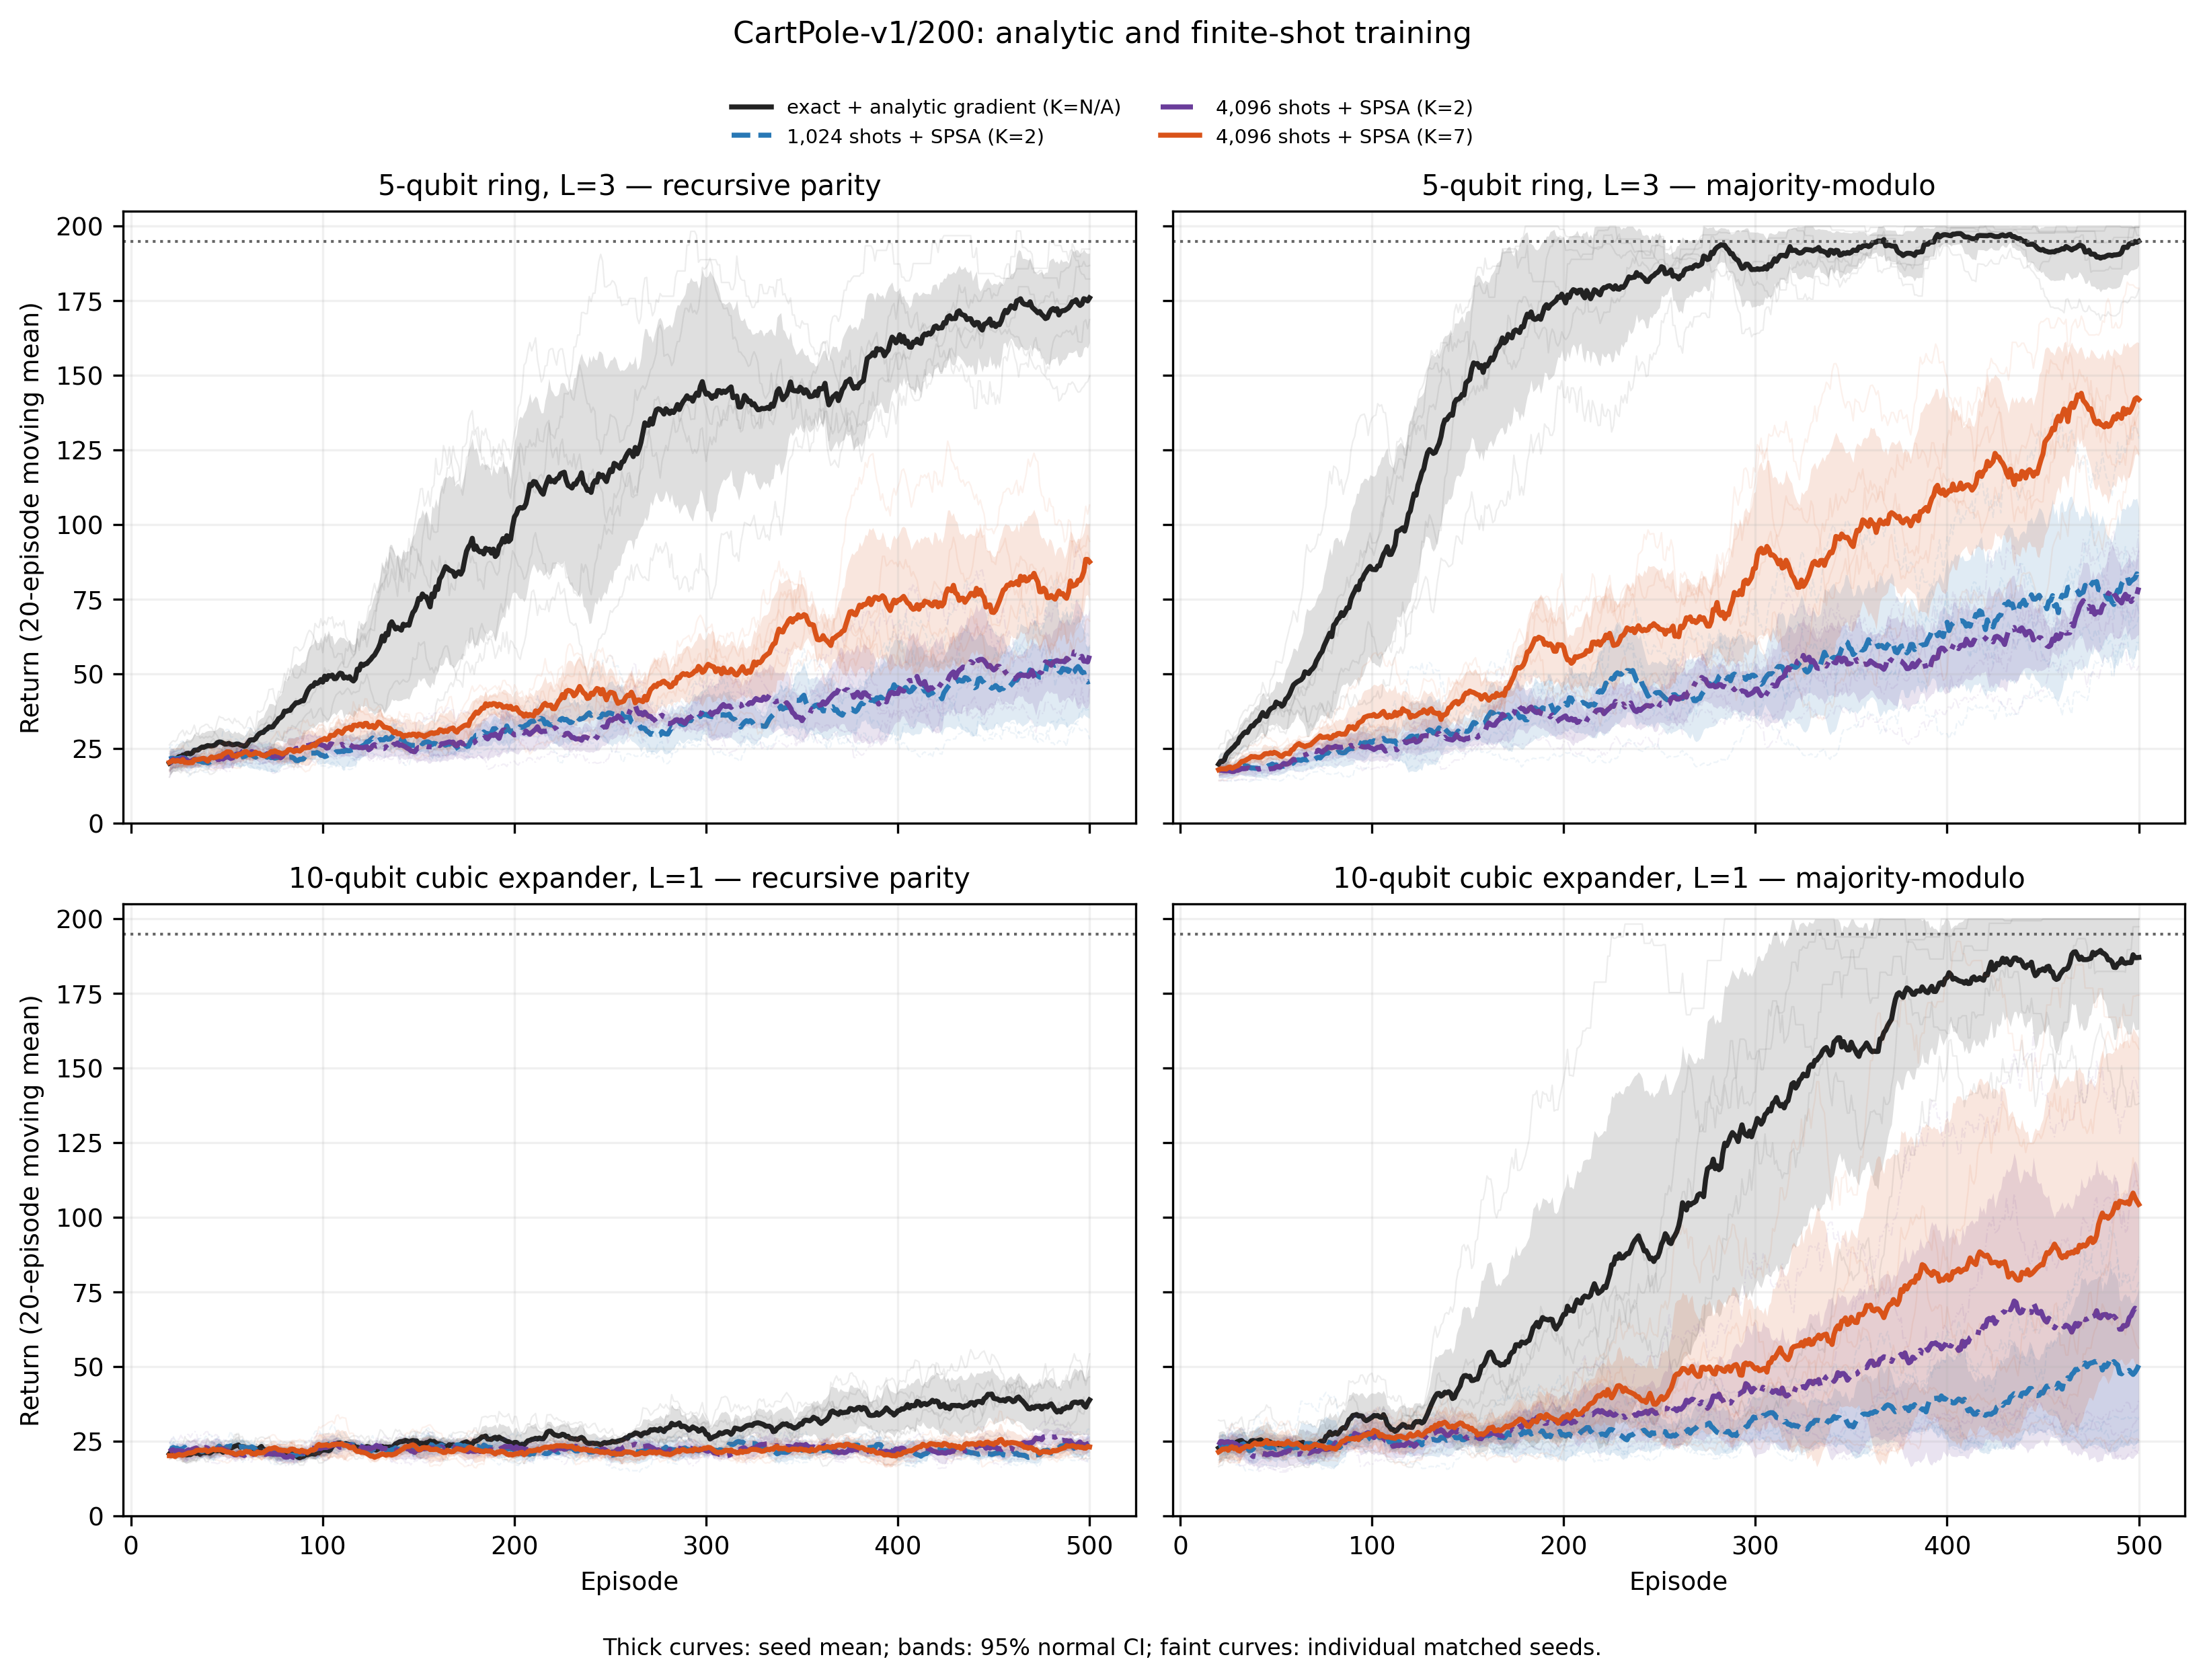

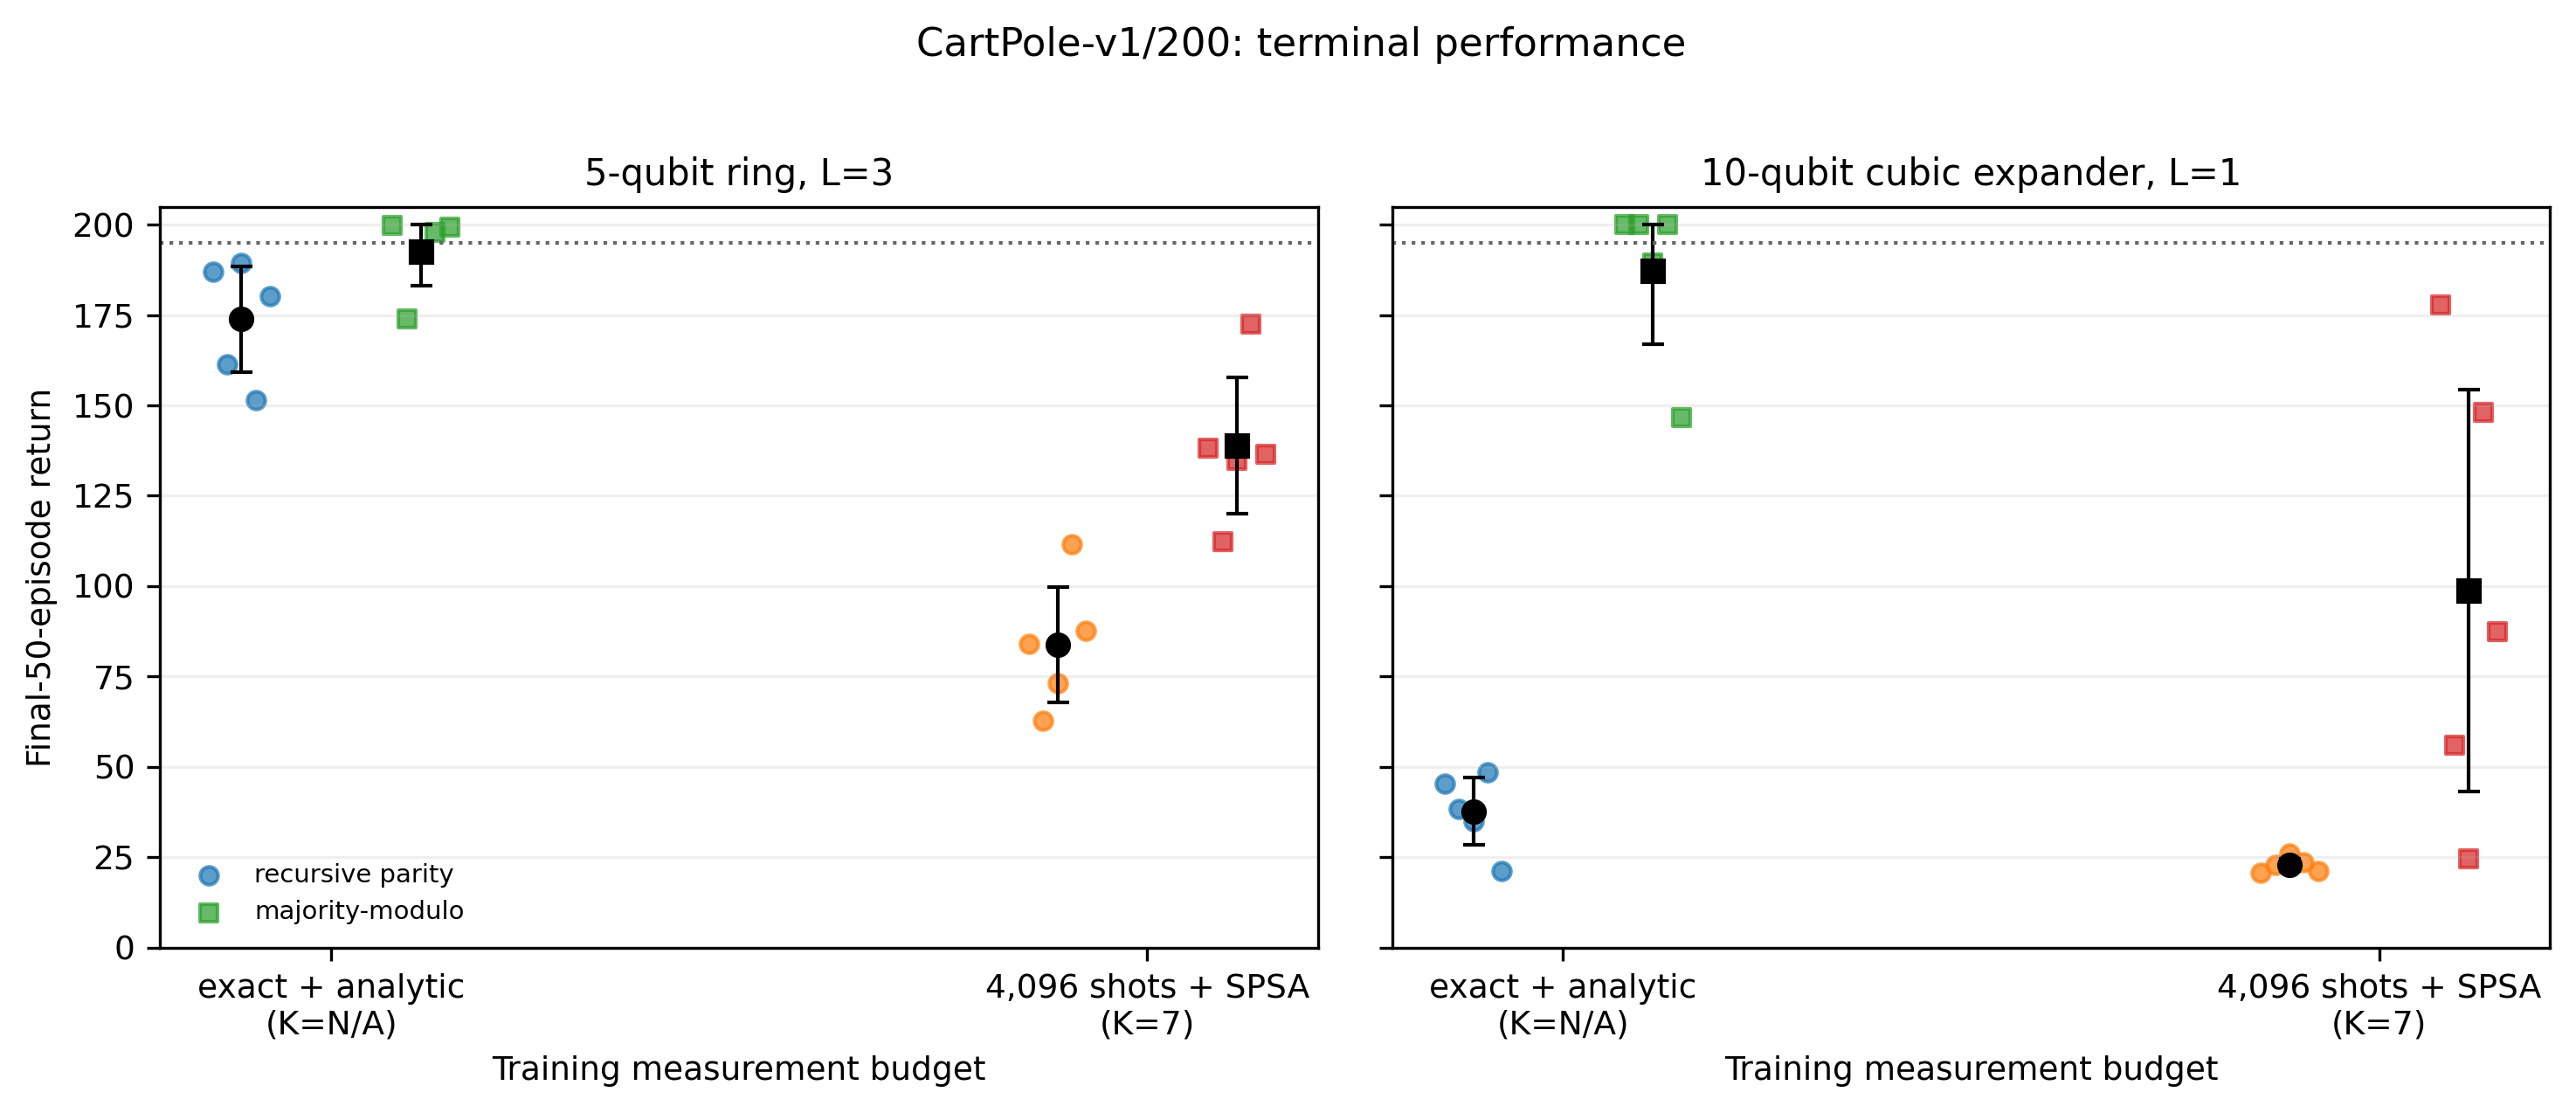

Saved: ./tests/finite_shot_cartpole_log2_directions_results/figures/log2_direction_finite_shot_learning_curves.png
Saved: ./tests/finite_shot_cartpole_log2_directions_results/figures/log2_direction_finite_shot_learning_curves.pdf
Saved: ./tests/finite_shot_cartpole_log2_directions_results/figures/log2_direction_final50_paired.png
Saved: ./tests/finite_shot_cartpole_log2_directions_results/figures/log2_direction_final50_paired.pdf


In [8]:
learning_mode_order = [
    "exact_analytic", "shots_1024", "shots_4096", "shots_4096_log2K"
]
terminal_mode_order = ["exact_analytic", "shots_4096_log2K"]
mode_labels = {
    "exact_analytic": "exact + analytic gradient (K=N/A)",
    "shots_1024": "1,024 shots + SPSA (K=2)",
    "shots_4096": "4,096 shots + SPSA (K=2)",
    "shots_4096_log2K": "4,096 shots + SPSA (K=7)",
}
terminal_mode_labels = {
    "exact_analytic": "exact + analytic\n(K=N/A)",
    "shots_4096_log2K": "4,096 shots + SPSA\n(K=7)",
}
mode_colors = {
    "exact_analytic": "#222222",
    "shots_1024": "#2878B5",
    "shots_4096": "#6A3D9A",
    "shots_4096_log2K": "#D95319",
}
mode_linestyles = {
    "exact_analytic": "-",
    "shots_1024": "--",
    "shots_4096": "-.",
    "shots_4096_log2K": "-",
}
policy_titles = {"parity": "recursive parity", "majority": "majority-modulo"}

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.6), dpi=300, sharex=True, sharey=True)
for row, (architecture, spec) in enumerate(ARCHITECTURES.items()):
    for col, policy_name in enumerate(POLICIES):
        ax = axes[row, col]
        for mode in learning_mode_order:
            subset = returns_df[
                (returns_df.architecture == architecture)
                & (returns_df.policy == policy_name)
                & (returns_df["mode"] == mode)
            ]
            pivot = subset.pivot(index="seed", columns="episode", values="return").sort_index()
            trajectories = pivot.to_numpy(float)
            window = 20
            smooth = np.stack([
                np.convolve(run, np.ones(window) / window, mode="valid")
                for run in trajectories
            ])
            episodes = np.arange(window, N_EPISODES + 1)
            mean = smooth.mean(axis=0)
            sem = smooth.std(axis=0, ddof=1) / np.sqrt(len(smooth))
            ci = 1.96 * sem
            color = mode_colors[mode]
            for seed_curve in smooth:
                ax.plot(episodes, seed_curve, color=color, linestyle=mode_linestyles[mode], alpha=0.08, linewidth=0.55)
            ax.fill_between(
                episodes,
                np.clip(mean - ci, 0, 200),
                np.clip(mean + ci, 0, 200),
                color=color, alpha=0.14, linewidth=0,
            )
            ax.plot(episodes, mean, color=color, linestyle=mode_linestyles[mode], label=mode_labels[mode])
        ax.axhline(SOLVED_THRESHOLD, color="#666666", linestyle=":", linewidth=1.0)
        ax.set_title(f"{spec['label']} — {policy_titles[policy_name]}")
        ax.set_ylim(0, 205)
        ax.grid(alpha=0.18)
        if row == 1:
            ax.set_xlabel("Episode")
        if col == 0:
            ax.set_ylabel("Return (20-episode moving mean)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.005))
fig.suptitle("CartPole-v1/200: analytic and finite-shot training", y=1.045)
fig.text(
    0.5, -0.01,
    "Thick curves: seed mean; bands: 95% normal CI; faint curves: individual matched seeds.",
    ha="center", va="top", fontsize=8,
)
fig.tight_layout()
main_png = FIGURES_DIR / "log2_direction_finite_shot_learning_curves.png"
main_pdf = FIGURES_DIR / "log2_direction_finite_shot_learning_curves.pdf"
fig.savefig(main_png, dpi=300, bbox_inches="tight")
fig.savefig(main_pdf, bbox_inches="tight")
plt.show()

# Terminal final-50 paired points.
fig2, axes2 = plt.subplots(1, 2, figsize=(10.0, 4.1), dpi=300, sharey=True)
for ax, (architecture, spec) in zip(axes2, ARCHITECTURES.items()):
    x_positions = np.arange(len(terminal_mode_order))
    offsets = {"parity": -0.11, "majority": 0.11}
    markers = {"parity": "o", "majority": "s"}
    for policy_name in POLICIES:
        for x, mode in zip(x_positions, terminal_mode_order):
            values = run_metadata_df[
                (run_metadata_df.architecture == architecture)
                & (run_metadata_df.policy == policy_name)
                & (run_metadata_df["mode"] == mode)
            ].sort_values("seed").final_50.to_numpy(float)
            jitter = np.linspace(-0.035, 0.035, len(values))
            ax.scatter(
                np.full(len(values), x + offsets[policy_name]) + jitter,
                values, marker=markers[policy_name], s=24, alpha=0.72,
                label=policy_titles[policy_name] if x == 0 else None,
            )
            point_mean = values.mean()
            half_width = 1.96 * values.std(ddof=1) / np.sqrt(len(values))
            interval_low = np.clip(point_mean - half_width, 0, 200)
            interval_high = np.clip(point_mean + half_width, 0, 200)
            ax.errorbar(
                x + offsets[policy_name], point_mean,
                yerr=np.array([[point_mean - interval_low], [interval_high - point_mean]]),
                color="black", marker=markers[policy_name], capsize=3, linewidth=1,
            )
    ax.axhline(195, color="#666666", linestyle=":", linewidth=1)
    ax.set_xticks(x_positions, [terminal_mode_labels[m] for m in terminal_mode_order])
    ax.set_title(spec["label"])
    ax.set_xlabel("Training measurement budget")
    ax.set_ylim(0, 205)
    ax.grid(axis="y", alpha=0.2)
axes2[0].set_ylabel("Final-50-episode return")
axes2[0].legend(frameon=False)
fig2.suptitle("CartPole-v1/200: terminal performance", y=1.02)
fig2.tight_layout()
terminal_png = FIGURES_DIR / "log2_direction_final50_paired.png"
terminal_pdf = FIGURES_DIR / "log2_direction_final50_paired.pdf"
fig2.savefig(terminal_png, dpi=300, bbox_inches="tight")
fig2.savefig(terminal_pdf, bbox_inches="tight")
plt.show()

print("Saved:", main_png)
print("Saved:", main_pdf)
print("Saved:", terminal_png)
print("Saved:", terminal_pdf)


In [9]:
try:
    git_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True
    ).strip()
    git_dirty = bool(subprocess.check_output(
        ["git", "status", "--porcelain"], cwd=ROOT, text=True
    ).strip())
except Exception:
    git_commit, git_dirty = None, None

# Prove the preserved source data stayed byte-for-byte unchanged.
for filename, expected in BASELINE_FILE_HASHES.items():
    actual = hashlib.sha256((BASELINE_RESULTS_DIR / filename).read_bytes()).hexdigest()
    assert actual == expected

config_metadata = {
    "created_utc": pd.Timestamp.utcnow().isoformat(),
    "source_notebook": str(ROOT / "tests" / "test_policy_training_efficiency_finite_shots.ipynb"),
    "notebook": str(ROOT / "tests" / "test_policy_training_efficiency_finite_shots_log2_directions.ipynb"),
    "preserved_baseline_results": str(BASELINE_RESULTS_DIR),
    "preserved_baseline_file_hashes": BASELINE_FILE_HASHES,
    "preserved_reporting_conditions": [
        "1,024 shots + SPSA (K=2)",
        "4,096 shots + SPSA (K=2)",
    ],
    "publication_curve_conditions": [
        "exact + analytic gradient (K=N/A)",
        "4,096 shots + SPSA (K=7)",
    ],
    "results_directory": str(RESULTS_DIR),
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "architectures": ARCHITECTURES,
    "parameter_count_audit": parameter_count_df.to_dict(orient="records"),
    "conditions": CONDITIONS,
    "policies": list(POLICIES),
    "episodes": N_EPISODES,
    "max_steps": MAX_STEPS,
    "terminal_metric": f"mean return over final {FINAL_WINDOW} episodes",
    "solved_metric": f"first full {SOLVED_WINDOW}-episode rolling mean >= {SOLVED_THRESHOLD}",
    "optimizer_freeze_rule": "at 5-episode boundary, mean of most recent up-to-100 returns >=195; interaction continues to episode 500",
    "preprocessing": "state / [2.4, 3.0, 0.2095, 3.5], clipped to [-3,3]",
    "finite_probability_rule": "Jeffreys alpha=0.5 per action: (count+0.5)/(shots+1)",
    "finite_gradient_estimator": "two-sided SPSA with K=ceil(log2 p) independent Rademacher directions/update and independent 4096-shot +/- losses",
    "parameter_count_definition": "all trainable scalar entries in input_scaling_params and circuit params",
    "training": TRAINING,
    "versions": {
        "python": platform.python_version(),
        "qasp": getattr(qasp, "__version__", "local checkout"),
        "pennylane": qml.__version__,
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "gymnasium": gym.__version__,
    },
    "git_commit": git_commit,
    "git_dirty": git_dirty,
}

with open(RESULTS_DIR / "experiment_config.json", "w") as handle:
    json.dump(config_metadata, handle, indent=2, default=str)

manifest_rows = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file():
        manifest_rows.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(RESULTS_DIR / "manifest.csv", index=False)

total_runtime = new_run_metadata_df.seconds.sum()
total_evaluations = int(new_run_metadata_df.total_circuit_evaluations.sum())
total_shots = int(new_run_metadata_df.total_circuit_shots.sum())
print(f"Aggregate serial training runtime: {total_runtime/3600:.3f} h")
print(f"Total NEW logical circuit evaluations: {total_evaluations:,}")
print(f"Total NEW finite circuit shots: {total_shots:,}")
print("Machine-readable files:")
display(manifest_df)


Aggregate serial training runtime: 0.361 h
Total NEW logical circuit evaluations: 7,378,845
Total NEW finite circuit shots: 30,223,749,120
Machine-readable files:


,path,bytes,sha256
0,episode_returns.csv,890259,9e853d6afef1d2404813ecf4d5d05cd532aef478ca349f...
1,experiment_config.json,5304,2960a07295248040d99633f7f3b2bb56e6cbf609c89660...
2,figures/log2_direction_final50_paired.pdf,22573,a27033aefa76ed93f2b3a963ff9adc59e95b5e6eafd670...
3,figures/log2_direction_final50_paired.png,136820,04332fb802582a88a25205cac96a1aae7340413d63635a...
4,figures/log2_direction_finite_shot_learning_cu...,396265,3b9dbdcab2d90b12815af4aa362dc0e516f711fec0c942...
5,figures/log2_direction_finite_shot_learning_cu...,1771415,f5695297c94463f3d5f70939f4ea12ef872708fbda2704...
6,manifest.csv,4119,a9c04567de6c5c1022295fb72719ab3a08525ed487c2d2...
7,paired_comparisons.csv,2411,964f6fef664d15e48218475796018d5ab9285ae155bc7c...
8,preserved_k2_1024_4096_episode_returns.csv,1558458,059c08231e8b6d3cc5d84c6f33c48c0aa4e8718496cdcb...
9,preserved_k2_1024_4096_metadata.csv,10259,50ff56ab297ca78488bab50e6f936747aebe64a6674cd0...


## Interpretation guardrails

- The preregistered terminal statistic remains final-50-episode return.
- “Solved” means a full rolling 100-episode mean of at least 195; the separate
  optimizer-freeze episode retains the source implementation's up-to-100 rule.
- The publication plot contains only the verified exact-analytic baseline and
  the new 4,096-shot \(K=\lceil\log_2 p\rceil\) condition.
- Bands are 95% normal intervals across five matched seeds and are clipped to
  the physical return range [0,200]. Paired bootstrap intervals resample seeds.
- The direct K-new minus K=2 comparison uses the preserved 4,096-shot results
  but does not add their curves to the publication plot.
- Preserved 1,024- and 4,096-shot K=2 summaries are retained with explicit K
  labels to quantify the effect of increasing shots alone; neither is added to
  the publication learning-curve plot.
- Here \(p\) is the full trainable optimizer dimension (90/65), not the number
  of effective gate arguments (45/35). Consequently, \(K=7\) for both models.
- Exact Born probabilities are used only to sample multinomial counts. No
  exact probability enters a finite-shot policy loss or gradient estimate.
